In [1]:
import pandas as pd
import matplotlib.pyplot as plt

crop_df = pd.read_csv('crop_yield.csv')

In [2]:
# First 10 rows
display(crop_df.head(10))

# Missing values
print(crop_df.isnull().sum())

# Data types
print(crop_df.dtypes)

# Statistical summary of numeric columns
display(crop_df.describe())

# Statistical summary of object columns
display(crop_df.describe(include='object'))

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64
FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object


,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


C:\Users\hp\AppData\Local\Temp\ipykernel_21032\3928692053.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(crop_df.describe(include='object'))


,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [3]:
# Remove rows with missing YIELD_KG
crop_df = crop_df.dropna(subset=['YIELD_KG'])

# Fill missing AREA_ACRES with mean
crop_df['AREA_ACRES'] = crop_df['AREA_ACRES'].fillna(
    crop_df['AREA_ACRES'].mean()
)

# Fill missing DISTRICT
crop_df['DISTRICT'] = crop_df['DISTRICT'].fillna('Unknown')

# Fill missing FERTILIZER_USED
crop_df['FERTILIZER_USED'] = crop_df['FERTILIZER_USED'].fillna('No')

# Fill missing YIELD_VALUE with mean
crop_df['YIELD_VALUE'] = crop_df['YIELD_VALUE'].fillna(
    crop_df['YIELD_VALUE'].mean()
)

In [4]:
# Convert HARVEST_DATE to datetime
crop_df['HARVEST_DATE'] = pd.to_datetime(
    crop_df['HARVEST_DATE'],
    format='%d/%m/%Y',
    errors='coerce'
)

# Remove F from FARM_ID and convert to integer
crop_df['FARM_ID'] = crop_df['FARM_ID'].str.replace('F', '').astype(int)

In [5]:
# Check missing values again
print(crop_df.isnull().sum())

# Check data types again
print(crop_df.dtypes)

# Display cleaned data
display(crop_df.head(10))

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64
FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object


,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,1,Wheat,1500.0,4.000000,2023-01-01,Sialkot,Rabi,Yes,30000
1,2,Wheat,1500.0,5.000000,2023-01-02,Multan,Rabi,No,30000
2,3,Wheat,2500.0,5.000000,2023-01-03,Faisalabad,Rabi,Yes,50000
3,4,Wheat,1500.0,4.412667,2023-01-04,Multan,Rabi,Yes,30000
4,5,Rice,1500.0,4.000000,2023-01-05,Faisalabad,Rabi,No,30000
5,6,Rice,2000.0,6.000000,2023-01-06,Faisalabad,Rabi,Yes,40000
6,7,Maize,1500.0,6.000000,2023-01-07,Faisalabad,Rabi,No,30000
7,8,Wheat,1500.0,5.000000,2023-01-08,Lahore,Rabi,No,30000
8,9,Wheat,2000.0,5.000000,2023-01-09,Faisalabad,Rabi,Yes,40000
9,10,Wheat,1500.0,3.000000,2023-01-10,Faisalabad,Rabi,Yes,30000


In [6]:
crop_yield = crop_df.groupby('CROP_TYPE').agg({
    'YIELD_KG': 'sum'
})

display(crop_yield)

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


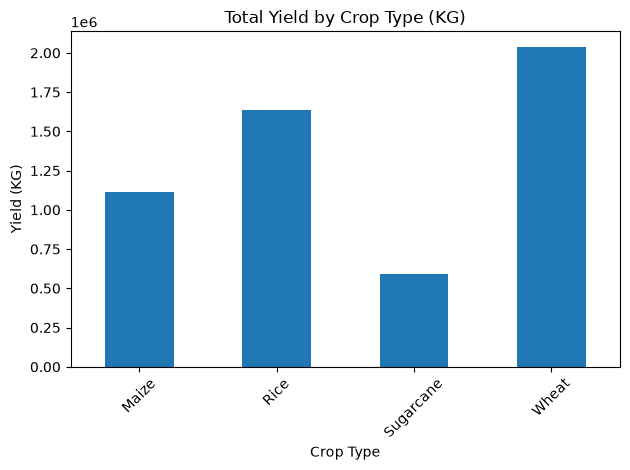

In [7]:
crop_yield.plot(kind='bar', legend=False)

plt.title('Total Yield by Crop Type (KG)')
plt.xlabel('Crop Type')
plt.ylabel('Yield (KG)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
yield_pivot = crop_df.pivot_table(
    values='YIELD_KG',
    index='HARVEST_DATE',
    aggfunc='sum'
)

display(yield_pivot)

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


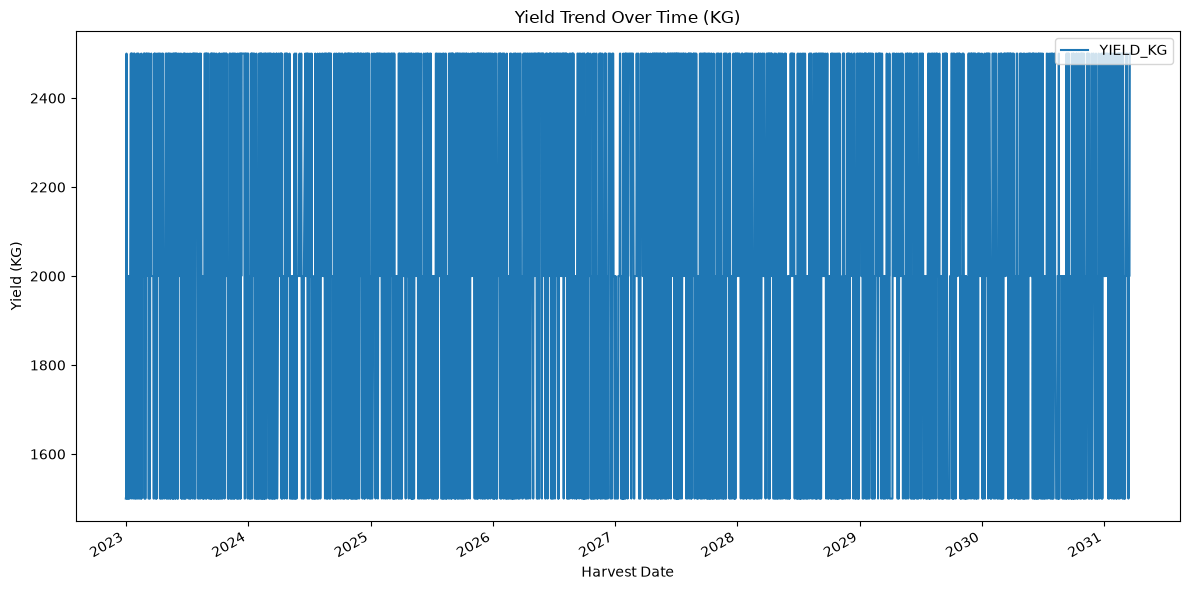

In [9]:
yield_pivot.plot(kind='line', figsize=(12, 6))

plt.title('Yield Trend Over Time (KG)')
plt.xlabel('Harvest Date')
plt.ylabel('Yield (KG)')
plt.tight_layout()

plt.savefig('crop_yield_trend.png')
plt.show()